# 01 Market Data and Momentum Jupyter Notebook

### Importing all necessary packages
    - yfinance: obtains market data from Yahoo Finance
    - pandas: works with structured data
    - numpy: quick math computations
    - matplotlib: creates plots/visualizations

In [35]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Downloading Market Data
    - created and added a returns column to market data
    - visualized first ten entries of market data

In [ ]:
df = yf.download(
    "AAPL",
    start = "2020-01-01",
    end = "2025-01-01",
    auto_adjust = True
    )

df.head()

df["return"] = df["Close"].pct_change()
df[["Close", "return"]].head(10)

[*********************100%***********************]  1 of 1 completed


Price,Close,return
Ticker,AAPL,
Date,,
2020-01-02,72.271545,NaN
2020-01-03,71.568916,-0.009722
2020-01-06,72.139198,0.007968
2020-01-07,71.799942,-0.004703
2020-01-08,72.954903,0.016086
2020-01-09,74.504539,0.021241
2020-01-10,74.672958,0.002261
2020-01-13,76.268295,0.021364


### Graph of AAPL Price over Date

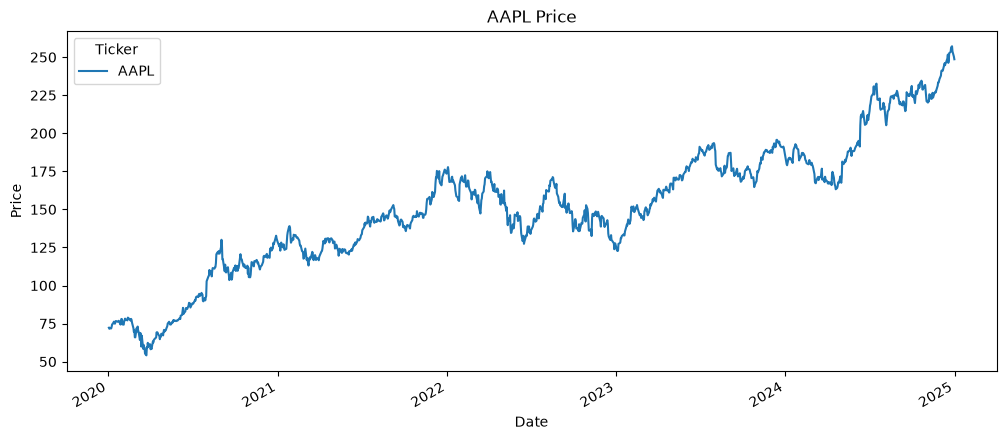

In [51]:
df["Close"].plot(figsize = (12, 5))
plt.title("AAPL Price")
plt.xlabel("Date")
plt.ylabel("Price")
plt.show()

### Graph of AAPL Returns over Date

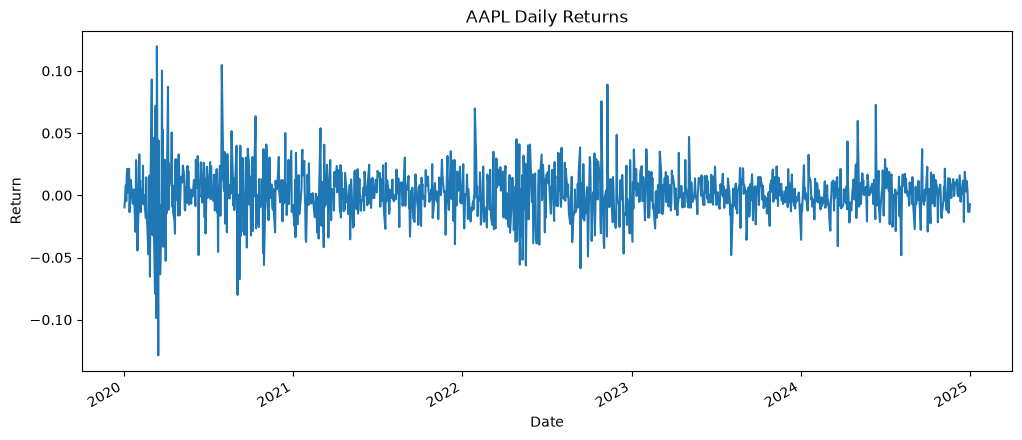

In [52]:
df["return"].plot(figsize = (12, 5))
plt.title("AAPL Daily Returns")
plt.xlabel("Date")
plt.ylabel("Return")
plt.show()

### 

In [53]:
df["momentum_20"] = df["Close"].pct_change(20)
df["position"] = np.where(df["momentum_20"] > 0, 1, 0)
df["strategy_return"] = df["position"].shift(1) * df["return"]

df["buy_hold_growth"] = (1 + df["return"]).cumprod()
df["strategy_growth"] = (1 + df["strategy_return"]).cumprod()

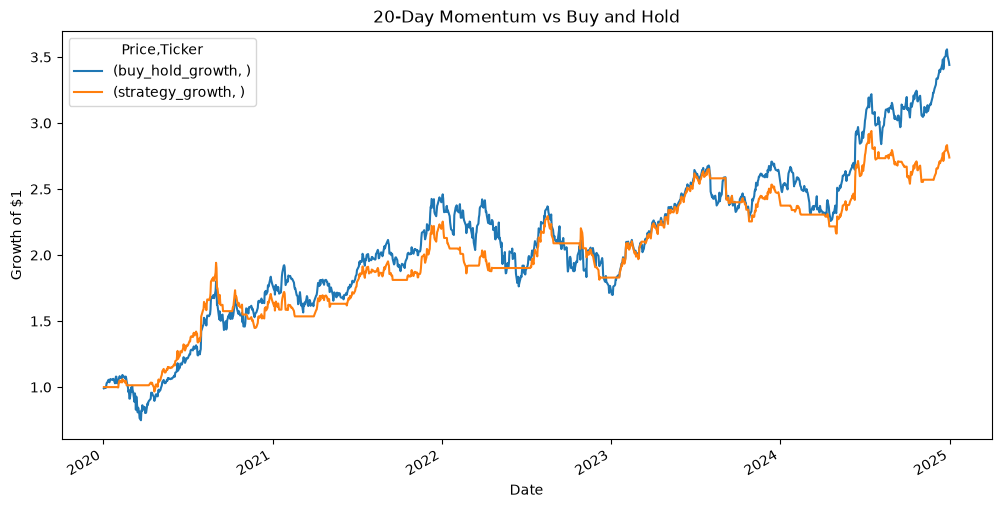

In [54]:
df[["buy_hold_growth", "strategy_growth"]].plot(figsize = (12, 6))
plt.title("20-Day Momentum vs Buy and Hold")
plt.ylabel("Growth of $1")
plt.show()

In [55]:
buy_hold_total = df["buy_hold_growth"].iloc[-1] - 1
strategy_total = df["strategy_growth"].iloc[-1] - 1

print("Buy and Hold Total Return:", buy_hold_total)
print("Strategy Total Return:", strategy_total)

Buy and Hold Total Return: 2.4400230724340957
Strategy Total Return: 1.7386603976017923


In [56]:
buy_hold_vol = df["return"].std() * np.sqrt(252)
strategy_vol = df["strategy_return"].std() * np.sqrt(252)

print("Buy and Hold Volatility:", buy_hold_vol)
print("Strategy Volatility:", strategy_vol)

Buy and Hold Volatility: 0.31678618153789306
Strategy Volatility: 0.20711618915643942


In [57]:
buy_hold_sharpe = (df["return"].mean() / df["return"].std()) * np.sqrt(252)
strategy_sharpe = (df["strategy_return"].mean() / df["strategy_return"].std()) * np.sqrt(252)

print("Buy and Hold Sharpe:", buy_hold_sharpe)
print("Strategy Sharpe:", strategy_sharpe)

Buy and Hold Sharpe: 0.9403559554138976
Strategy Sharpe: 1.0785164683172774


In [58]:
df["strategy_peak"] = df["strategy_growth"].cummax()
df["strategy_drawdown"] = (df["strategy_growth"] / df["strategy_peak"] - 1)

max_drawdown = df["strategy_drawdown"].min()

print("Strategy Max Drawdown:", max_drawdown)

Strategy Max Drawdown: -0.2542239027214265


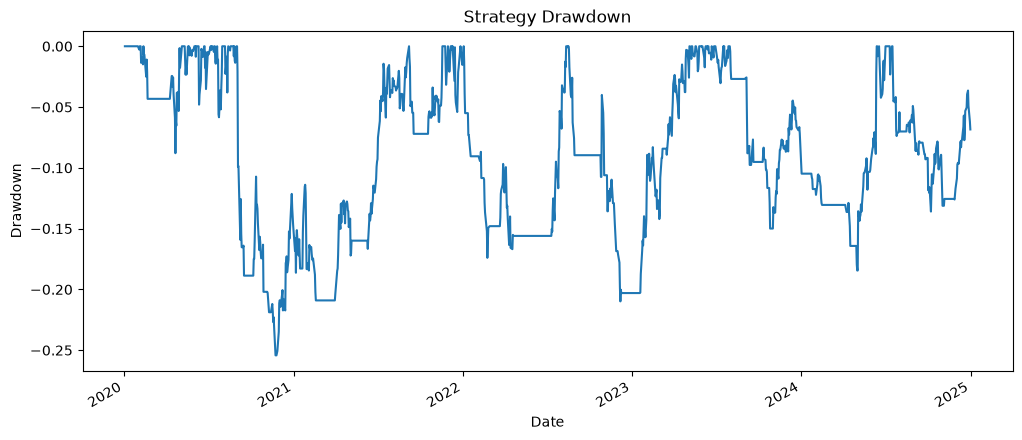

In [59]:
df["strategy_drawdown"].plot(figsize = (12, 5))
plt.title("Strategy Drawdown")
plt.xlabel("Date")
plt.ylabel("Drawdown")
plt.show()

In [60]:
close = df["Close"].squeeze()
returns = close.pct_change()

for lookback in [5, 10, 20, 50, 100]:
    momentum = close.pct_change(lookback)
    position = (momentum > 0).astype(int)
    strategy_return = position.shift(1) * returns

    sharpe = (strategy_return.mean() / strategy_return.std()) * np.sqrt(252)

    print(f"{lookback}-day lookback Sharpe: {sharpe:.3f}")

5-day lookback Sharpe: 0.698
10-day lookback Sharpe: 1.016
20-day lookback Sharpe: 1.079
50-day lookback Sharpe: 0.832
100-day lookback Sharpe: 0.714


In [61]:
train = df.loc[:"2022-12-31"].copy()
test = df.loc["2023-01-01":].copy()

In [62]:
def momentum_strategy(data, lookback):
    close = data["Close"].squeeze()
    returns = close.pct_change()

    momentum = close.pct_change(lookback)
    position = (momentum > 0).astype(int)

    strategy_return = position.shift(1) * returns

    sharpe = (strategy_return.mean() / strategy_return.std()) * np.sqrt(252)

    return sharpe

In [63]:
for lookback in [5, 10, 20, 50, 100]:
    sharpe = momentum_strategy(train, lookback)
    print(lookback, sharpe)

5 0.5458096171785487
10 0.7361901697277833
20 0.9982203934013514
50 0.6098757204143176
100 0.7107414543268844
